# Self-Loop Detection and Removal Test in Random Networks

In [ ]:
# Environment and path setup (same pattern used in PiaNo.ipynb)
import math
import sys
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")
print(f"Files available: {os.listdir(utils_path)}")

Mounted at /content/drive
Environment: Google Colab
Utils path: /content/drive/MyDrive/ColabProject/utils
Files available: ['filtered_paths.py', 'utility_reset.py', 'nextSteps.txt', 'path_pairs_of_lines vs  path_pairs_of_edges.txt', 'region_checks.py', 'plotting_old.py', 'point_generator.py', 'boundary_utils.py', 'pdf_generator.py', 'rebuild_experiments.py', 'test_merge.py', 'edge_discovery.py', 'result_exporter.py', 'intersection_utils.py', 'pruning.py', 'plotting.py', 'experiment_manager.py', 'test_networks.py', 'pipeline_utils.py', 'path_analysis.py', 'laplacian_utils.py', 'pipeline_utils_src.py', 'impedance_calculator.py', 'self_loop_utils.py', 'network_visualization.py', '__pycache__', 'loop_topology_utils.py', 'node_loop_visualization.py', 'node_loop_test_runner.py', 'self_loops.py']


In [ ]:
# Reusing exactly the functions that already exist in the project
from point_generator import *
from region_checks import *
from intersection_utils import *
from path_analysis import *
from plotting import *
from pruning import *

# New module, created only for this task (does not modify anything existing)
from self_loops import detect_self_loops, remove_self_loops

import random
import numpy as np

## Why there should be no self-loops

`identify_intersections` (`intersection_utils.py`) loops over `for i in range(N): for j in range(i + 1, N)`, so a stick is never paired with itself and `graph` cannot contain an `(i, i)` entry. `find_path` likewise skips `i == current_node` when it builds `path_pairs_of_edges`.

The test is still worth running: it is a cheap regression check if the generator or the intersection code changes, and it exercises `detect_self_loops` and `remove_self_loops` on real data. `run_random_network_self_loop_case` runs independent random repetitions of one `(N, a)` configuration with the `PiaNo.ipynb` pipeline, including its skipping of nodes already in `all_connected_nodes`.

In [ ]:
def run_random_network_self_loop_case(case_id, N, a, n_trials=30, base_seed=0, plot_example=True):
    """
    Generates `n_trials` independent random networks for the (N, a)
    configuration using the existing pipeline (generate_points +
    identify_intersections + find_path, with the same
    boundary_condition_source/drain and do_not_check logic used in
    PiaNo.ipynb), and checks, in each one, whether self-loops appear:

    - at the segment level: entries (i, i) in `graph`;
    - at the path level: edges (k, k) in `path_pairs_of_edges`.

    At the end, it exercises `remove_self_loops` on an example trial
    (should be a safe no-op on a real, clean network) and plots that
    example network with the existing plotting.py functions.
    """
    total_graph_entries = 0
    total_seg_self_loops = 0
    total_path_edges_examined = 0
    total_node_self_loops = 0
    n_intersections_list = []

    example = None  # keeps the first trial for plotting/demonstration

    for trial in range(n_trials):
        seed = base_seed + trial
        random.seed(seed)
        np.random.seed(seed)

        points_1, points_2, angles, graph = [], [], [], []
        intersections_points, intersected_line_1, intersected_line_2 = [], [], []

        generate_points(N, points_1, points_2, angles, a)
        intersections_points, intersected_line_1, intersected_line_2, graph = identify_intersections(
            points_1, points_2, intersections_points, intersected_line_1,
            intersected_line_2, graph, angles, a, N
        )

        n_intersections_list.append(len(intersections_points))
        total_graph_entries += len(graph)

        # 1) Self-loops at the segment level (graph)
        seg_loops = detect_self_loops(graph, verbose=False)
        total_seg_self_loops += len(seg_loops)

        # 2) Self-loops at the path level (find_path), replicating
        #    exactly the logic from PiaNo.ipynb (boundary + do_not_check)
        boundary_condition_source, boundary_condition_drain = [], []
        for i in range(len(intersections_points)):
            if intersections_points[i][0] < 0.1:
                boundary_condition_source.append(i)
            elif intersections_points[i][0] > 0.9:
                boundary_condition_drain.append(i)

        all_connected_nodes = []
        for i in boundary_condition_source:
            do_not_check = 0
            number_path = len(all_connected_nodes)
            for k in range(number_path):
                if i in all_connected_nodes[k]:
                    do_not_check = 1
            if do_not_check == 0:
                nodes, pair_of_lines, pair_of_edges, path_perc = find_path(intersections_points, graph, i)
                all_connected_nodes.append(nodes)
                total_path_edges_examined += len(pair_of_edges)
                total_node_self_loops += sum(1 for e in pair_of_edges if e[0] == e[1])

        if trial == 0:
            example = dict(
                points_1=points_1, points_2=points_2,
                intersected_line_1=intersected_line_1,
                intersected_line_2=intersected_line_2,
                intersections_points=intersections_points,
                graph=graph,
            )

    print(f"=== Case {case_id}: N={N}, a={a}  ({n_trials} independent random networks) ===")
    print(f"  Intersections per trial (min/mean/max): "
          f"{min(n_intersections_list)} / {sum(n_intersections_list)/len(n_intersections_list):.1f} / {max(n_intersections_list)}")
    print(f"  Total graph entries examined:                {total_graph_entries}")
    print(f"  Self-loops at the segment level (graph):     {total_seg_self_loops}")
    print(f"  Path edges examined (find_path):             {total_path_edges_examined}")
    print(f"  Self-loops at the path level (find_path):    {total_node_self_loops}")

    # Exercises remove_self_loops on the example network (trial 0)
    filtered_graph, filtered_points, removed = remove_self_loops(
        example['graph'], example['intersections_points'], verbose=True
    )
    consistent = (
        len(filtered_graph) == len(example['graph']) - len(removed)
        and len(filtered_points) == len(example['intersections_points']) - len(removed)
    )
    print(f"  remove_self_loops on the example trial -> removed: {len(removed)}, "
          f"lengths consistent: {consistent}")

    if plot_example:
        plot_lines(N, example['points_1'], example['points_2'])
        plot_lines_intersection(
            N, example['points_1'], example['points_2'],
            example['intersected_line_1'], example['intersected_line_2'],
            example['intersections_points']
        )

    print()

    return {
        'case_id': case_id, 'N': N, 'a': a, 'n_trials': n_trials,
        'total_graph_entries': total_graph_entries,
        'total_seg_self_loops': total_seg_self_loops,
        'total_path_edges_examined': total_path_edges_examined,
        'total_node_self_loops': total_node_self_loops,
        'removed_on_example': len(removed),
        'consistent': consistent,
    }

all_results = []

## Test case 1: sparse network (small N, small `a`)

`N = 10`, `a = 0.3`: few short sticks, few intersections expected.

=== Case 1: N=10, a=0.3  (30 independent random networks) ===
  Intersections per trial (min/mean/max): 0 / 3.3 / 9
  Total graph entries examined:                100
  Self-loops at the segment level (graph):     0
  Path edges examined (find_path):             1
  Self-loops at the path level (find_path):    0
  No self-loops found.
  remove_self_loops on the example trial -> removed: 0, lengths consistent: True


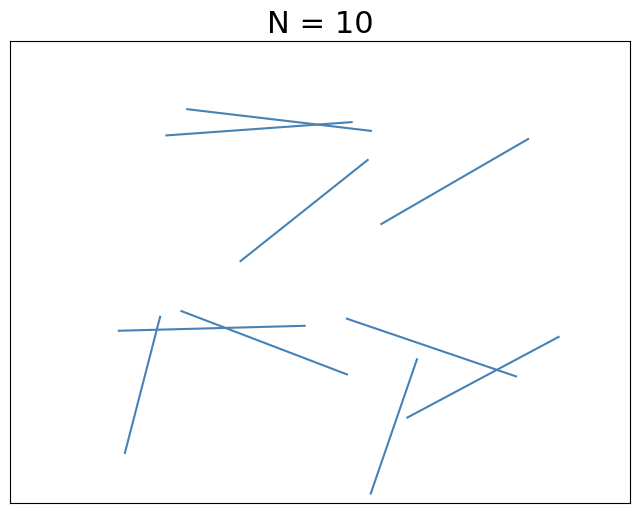

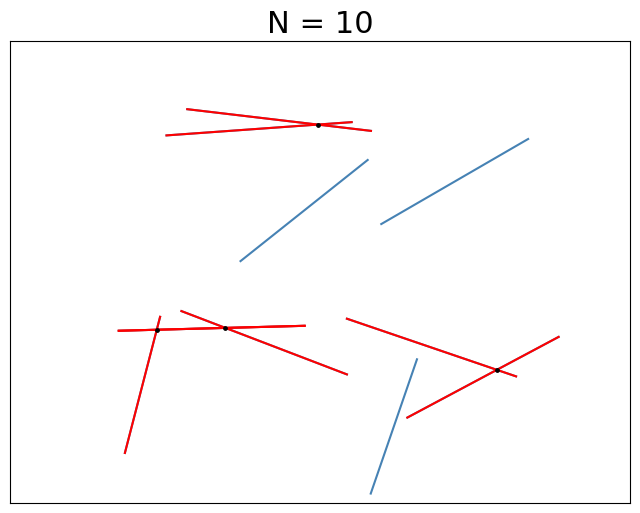

In [ ]:
result_1 = run_random_network_self_loop_case(case_id=1, N=10, a=0.3, n_trials=30, base_seed=100)
all_results.append(result_1)

## Test case 2: `PiaNo.ipynb` default configuration

`N = 30`, `a = 0.70`: the same values used as the "main variables"
in the original notebook, to serve as a direct comparison.

=== Case 2: N=30, a=0.7  (30 independent random networks) ===
  Intersections per trial (min/mean/max): 149 / 185.3 / 222
  Total graph entries examined:                5559
  Self-loops at the segment level (graph):     0
  Path edges examined (find_path):             4153
  Self-loops at the path level (find_path):    0
  No self-loops found.
  remove_self_loops on the example trial -> removed: 0, lengths consistent: True


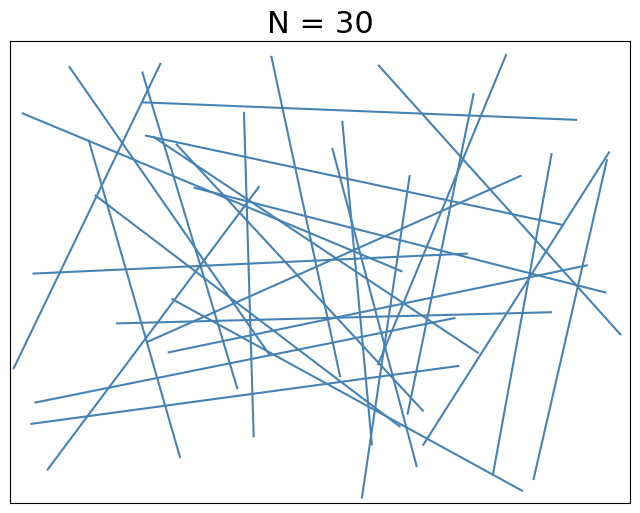

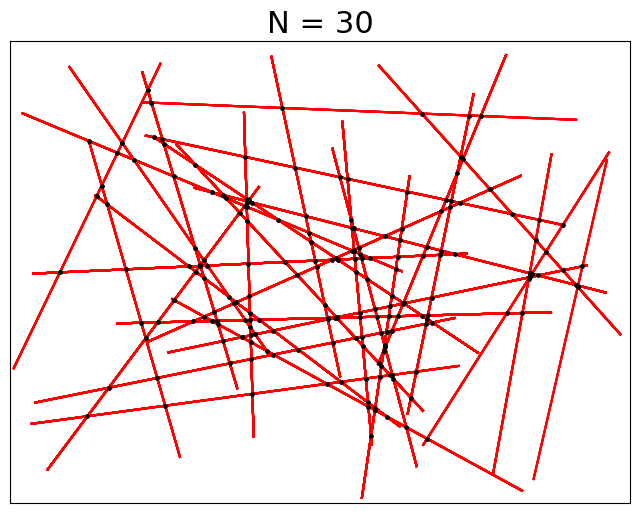

In [ ]:
result_2 = run_random_network_self_loop_case(case_id=2, N=30, a=0.70, n_trials=30, base_seed=200)
all_results.append(result_2)

## Test case 3: intermediate network

`N = 50`, `a = 0.5`: more sticks, intermediate length.

=== Case 3: N=50, a=0.5  (30 independent random networks) ===
  Intersections per trial (min/mean/max): 218 / 261.2 / 325
  Total graph entries examined:                7837
  Self-loops at the segment level (graph):     0
  Path edges examined (find_path):             7299
  Self-loops at the path level (find_path):    0
  No self-loops found.
  remove_self_loops on the example trial -> removed: 0, lengths consistent: True


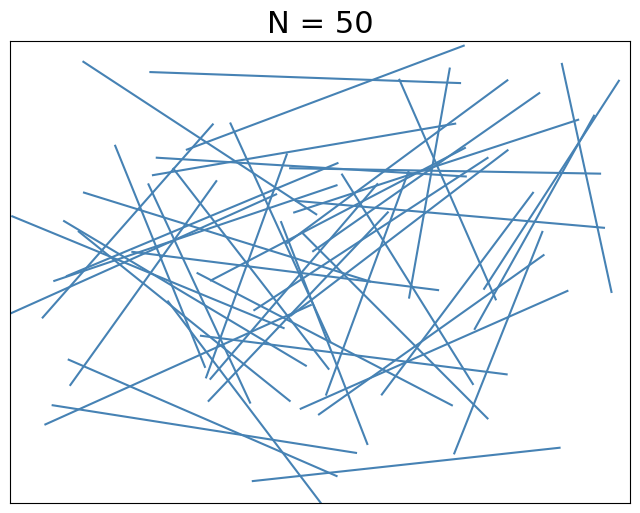

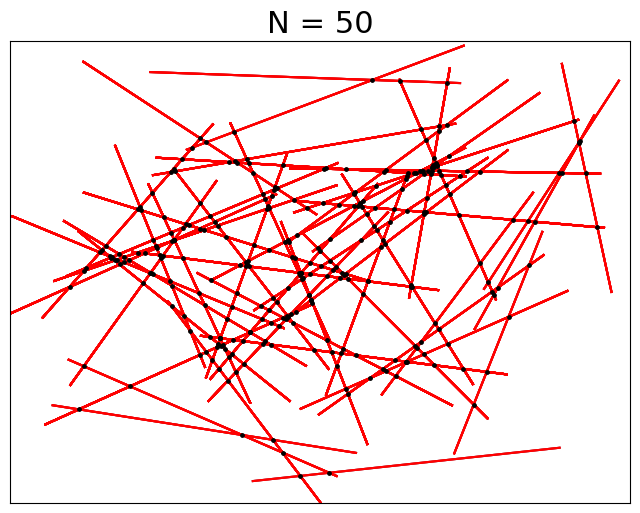

In [ ]:
result_3 = run_random_network_self_loop_case(case_id=3, N=50, a=0.5, n_trials=30, base_seed=300)
all_results.append(result_3)

## Test case 4: dense network (large N, small `a`)

`N = 100`, `a = 0.2`: many short sticks, good coverage of high
segment-density cases.

=== Case 4: N=100, a=0.2  (20 independent random networks) ===
  Intersections per trial (min/mean/max): 118 / 148.2 / 170
  Total graph entries examined:                2964
  Self-loops at the segment level (graph):     0
  Path edges examined (find_path):             875
  Self-loops at the path level (find_path):    0
  No self-loops found.
  remove_self_loops on the example trial -> removed: 0, lengths consistent: True


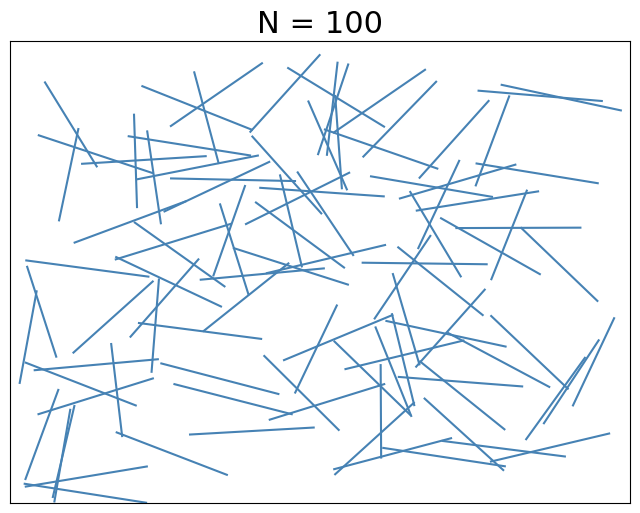

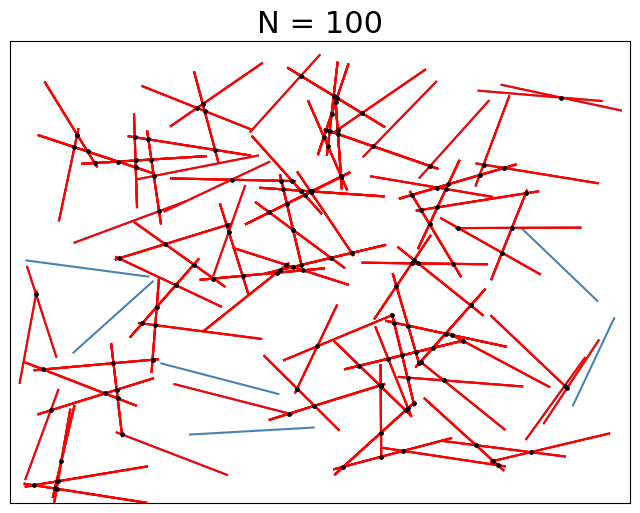

In [ ]:
result_4 = run_random_network_self_loop_case(case_id=4, N=100, a=0.2, n_trials=20, base_seed=400)
all_results.append(result_4)

## Test case 5: long sticks, close to the geometric limit

`N = 15`, `a = 1.2`: sticks that cross nearly the whole unit square, close to the limit `sqrt(2) ≈ 1.4142` that `generate_points` enforces under the `reject` boundary rule used when this notebook ran.

=== Case 5: N=15, a=1.2  (30 independent random networks) ===
  Intersections per trial (min/mean/max): 61 / 77.7 / 87
  Total graph entries examined:                2330
  Self-loops at the segment level (graph):     0
  Path edges examined (find_path):             1352
  Self-loops at the path level (find_path):    0
  No self-loops found.
  remove_self_loops on the example trial -> removed: 0, lengths consistent: True


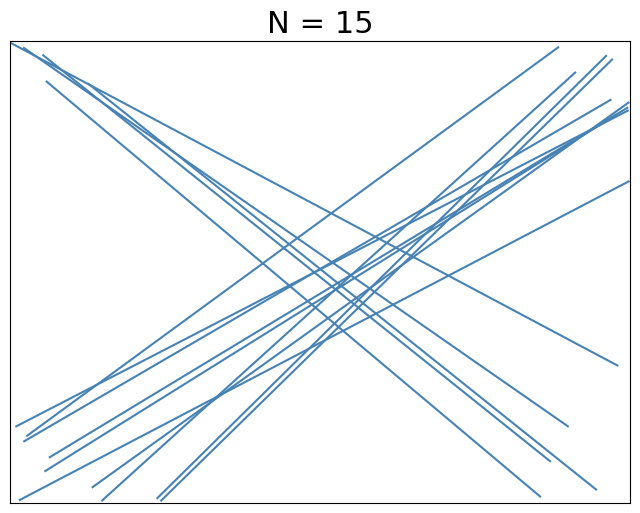

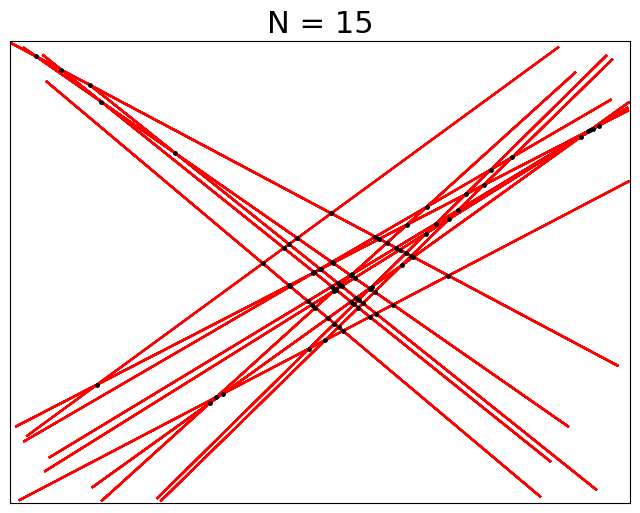

In [ ]:
result_5 = run_random_network_self_loop_case(case_id=5, N=15, a=1.2, n_trials=30, base_seed=500)
all_results.append(result_5)

## Consolidated summary of the 5 cases

Table with the total graph entries and path edges examined in each
configuration, and how many self-loops were found (expected: zero, at
both levels, in all cases).

In [ ]:
print(f"{'Case':<6}{'N':<6}{'a':<8}{'trials':<8}{'graph_entries':<16}{'seg_loops':<12}{'path_edges':<12}{'node_loops':<12}")
for r in all_results:
    print(f"{r['case_id']:<6}{r['N']:<6}{r['a']:<8}{r['n_trials']:<8}"
          f"{r['total_graph_entries']:<16}{r['total_seg_self_loops']:<12}"
          f"{r['total_path_edges_examined']:<12}{r['total_node_self_loops']:<12}")

total_seg = sum(r['total_seg_self_loops'] for r in all_results)
total_node = sum(r['total_node_self_loops'] for r in all_results)
total_graph = sum(r['total_graph_entries'] for r in all_results)
total_edges = sum(r['total_path_edges_examined'] for r in all_results)

print()
print(f"Grand total: {total_graph} graph entries and {total_edges} path edges "
      f"examined across {sum(r['n_trials'] for r in all_results)} random networks.")

assert total_seg == 0, "Self-loop found at the segment level!"
assert total_node == 0, "Self-loop found at the path level!"
assert all(r['consistent'] for r in all_results), "remove_self_loops became inconsistent in some case!"

print("OK: no self-loops found in any of the random networks tested, "
      "in any of the 5 cases, and remove_self_loops behaved as a safe "
      "no-op in all examples.")

Case  N     a       trials  graph_entries   seg_loops   path_edges  node_loops  
1     10    0.3     30      100             0           1           0           
2     30    0.7     30      5559            0           4153        0           
3     50    0.5     30      7837            0           7299        0           
4     100   0.2     20      2964            0           875         0           
5     15    1.2     30      2330            0           1352        0           

Grand total: 18790 graph entries and 13680 path edges examined across 140 random networks.
OK: no self-loops found in any of the random networks tested, in any of the 5 cases, and remove_self_loops behaved as a safe no-op in all examples.


## Unit-level check of the functions

Not one of the random-network cases: a tiny hand-made `graph` with an `(i, i)` entry confirms that `detect_self_loops` finds it and `remove_self_loops` removes it.

In [ ]:
toy_graph = [(0, 1), (1, 2), (3, 3), (2, 4)]
toy_points = [(0.05, 0.5), (0.4, 0.5), (0.6, 0.5), (0.95, 0.5)]

print("Toy graph (with a fabricated self-loop at (3,3)):", toy_graph)
loops = detect_self_loops(toy_graph)
assert loops == [2]

filtered_graph, filtered_points, removed = remove_self_loops(toy_graph, toy_points)
print("After remove_self_loops:", filtered_graph)
assert filtered_graph == [(0, 1), (1, 2), (2, 4)]
assert removed == [2]
print("OK: detect_self_loops/remove_self_loops work correctly when a self-loop exists.")

Toy graph (with a fabricated self-loop at (3,3)): [(0, 1), (1, 2), (3, 3), (2, 4)]
  Self-loops found: 1 at indices [2]
    graph[2] = (3, 3)
  Self-loops found: 1 at indices [2]
    graph[2] = (3, 3)
  Removed 1 self-loop(s). graph: 4 -> 3 entries | intersections_points: 4 -> 3 entries
After remove_self_loops: [(0, 1), (1, 2), (2, 4)]
OK: detect_self_loops/remove_self_loops work correctly when a self-loop exists.
